# Book-Crossing Recommender System

End-to-end data-mining assignment: ingest the Book-Crossing data into Bronze,
inspect and clean it into Silver, build a sparse book-user Gold matrix, and
generate item-based collaborative-filtering recommendations.

Run the cells from top to bottom. The source archive is downloaded only once;
the Parquet and sparse-matrix outputs are written to `bronze/`, `silver/`, and
`gold/` under the current working directory.

In [1]:
from importlib.util import find_spec
import subprocess
import sys

required_packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "pyarrow": "pyarrow",
    "IPython": "ipython",
}
missing_packages = [
    package
    for module, package in required_packages.items()
    if find_spec(module) is None
]
if missing_packages:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", *missing_packages]
    )
    import site
    import importlib

    sys.path.append(site.getusersitepackages())
    importlib.invalidate_caches()

from pathlib import Path
from zipfile import ZipFile
from urllib.request import urlretrieve
from datetime import datetime, timezone
import json
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display
from scipy.sparse import csr_matrix, save_npz
from sklearn.neighbors import NearestNeighbors

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("matplotlib", "inline")

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)

ROOT = Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
BRONZE_DIR = ROOT / "bronze"
SILVER_DIR = ROOT / "silver"
GOLD_DIR = ROOT / "gold"
for directory in (RAW_DIR, BRONZE_DIR, SILVER_DIR, GOLD_DIR):
    directory.mkdir(parents=True, exist_ok=True)

DATA_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
ARCHIVE_PATH = RAW_DIR / "book-crossings.zip"
if not ARCHIVE_PATH.exists():
    print(f"Downloading dataset to {ARCHIVE_PATH} ...")
    urlretrieve(DATA_URL, ARCHIVE_PATH)
else:
    print(f"Using cached dataset: {ARCHIVE_PATH}")

with ZipFile(ARCHIVE_PATH) as archive:
    archive.extractall(RAW_DIR)

CSV_FILES = {
    "users": RAW_DIR / "BX-Users.csv",
    "books": RAW_DIR / "BX-Books.csv",
    "ratings": RAW_DIR / "BX-Book-Ratings.csv",
}
for name, path in CSV_FILES.items():
    if not path.is_file():
        raise FileNotFoundError(f"Expected {name} CSV in dataset archive: {path}")

print("Data lake folders:", [str(path.relative_to(ROOT)) for path in
                            (BRONZE_DIR, SILVER_DIR, GOLD_DIR)])

Using cached dataset: /Users/apple/Desktop/DM/data/raw/book-crossings.zip
Data lake folders: ['bronze', 'silver', 'gold']


## Step 1 — Bronze ingestion

The source uses semicolon delimiters and a Windows-1252/Latin-1-compatible
encoding. Bronze preserves the parsed source columns and values without
cleaning; the only added field is the UTC ingestion timestamp.

In [2]:
bronze = {}
ingested_at = pd.Timestamp(datetime.now(timezone.utc))
for name, path in CSV_FILES.items():
    frame = pd.read_csv(
        path, sep=";", encoding="latin-1", escapechar="\\", low_memory=False
    )
    frame["ingestion_timestamp"] = ingested_at
    frame.to_parquet(BRONZE_DIR / f"{name}.parquet", index=False)
    bronze[name] = frame
    print(f"{name}: {frame.shape} -> {BRONZE_DIR / f'{name}.parquet'}")

users_bronze = bronze["users"]
books_bronze = bronze["books"]
ratings_bronze = bronze["ratings"]

users: (278858, 4) -> /Users/apple/Desktop/DM/bronze/users.parquet


books: (271379, 9) -> /Users/apple/Desktop/DM/bronze/books.parquet
ratings: (1149780, 4) -> /Users/apple/Desktop/DM/bronze/ratings.parquet


## Step 2 — Bronze EDA

The following profiles and plots are calculated from the downloaded data.
Ratings of zero mean "no explicit rating" in this dataset and are not
preferences. Ages below 5 or above 100 and publication years equal to zero or
later than the current year are treated as invalid during Silver cleaning.


USERS — shape: (278858, 4)


,dtype,missing_values,missing_percent
User-ID,int64,0,0.00
Location,str,0,0.00
Age,float64,110762,39.72
ingestion_timestamp,"datetime64[us, UTC]",0,0.00


Exact duplicate rows: 0

BOOKS — shape: (271379, 9)


,dtype,missing_values,missing_percent
ISBN,str,0,0.0
Book-Title,str,0,0.0
Book-Author,str,2,0.0
Year-Of-Publication,int64,0,0.0
Publisher,str,2,0.0
Image-URL-S,str,0,0.0
Image-URL-M,str,0,0.0
Image-URL-L,str,0,0.0
ingestion_timestamp,"datetime64[us, UTC]",0,0.0


Exact duplicate rows: 0

RATINGS — shape: (1149780, 4)


,dtype,missing_values,missing_percent
User-ID,int64,0,0.0
ISBN,str,0,0.0
Book-Rating,int64,0,0.0
ingestion_timestamp,"datetime64[us, UTC]",0,0.0


Exact duplicate rows: 0

Rating value counts (including zero):


Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64


EDA findings:
- users_age_missing: 110762
- users_age_below_5: 882
- users_age_above_100: 366
- books_year_missing_or_non_numeric: 0
- books_year_zero: 4619
- books_year_future: 11
- ratings_zero: 716109
- ratings_outside_0_to_10: 0
- ratings_per_user_min_median_max: (1, 1.0, 13602)
- ratings_per_book_min_median_max: (1, 1.0, 2502)
- possible_user_book_pairs: 75676205182
- observed_unique_user_book_pairs: 1149780
- matrix_density_percent: 0.001519


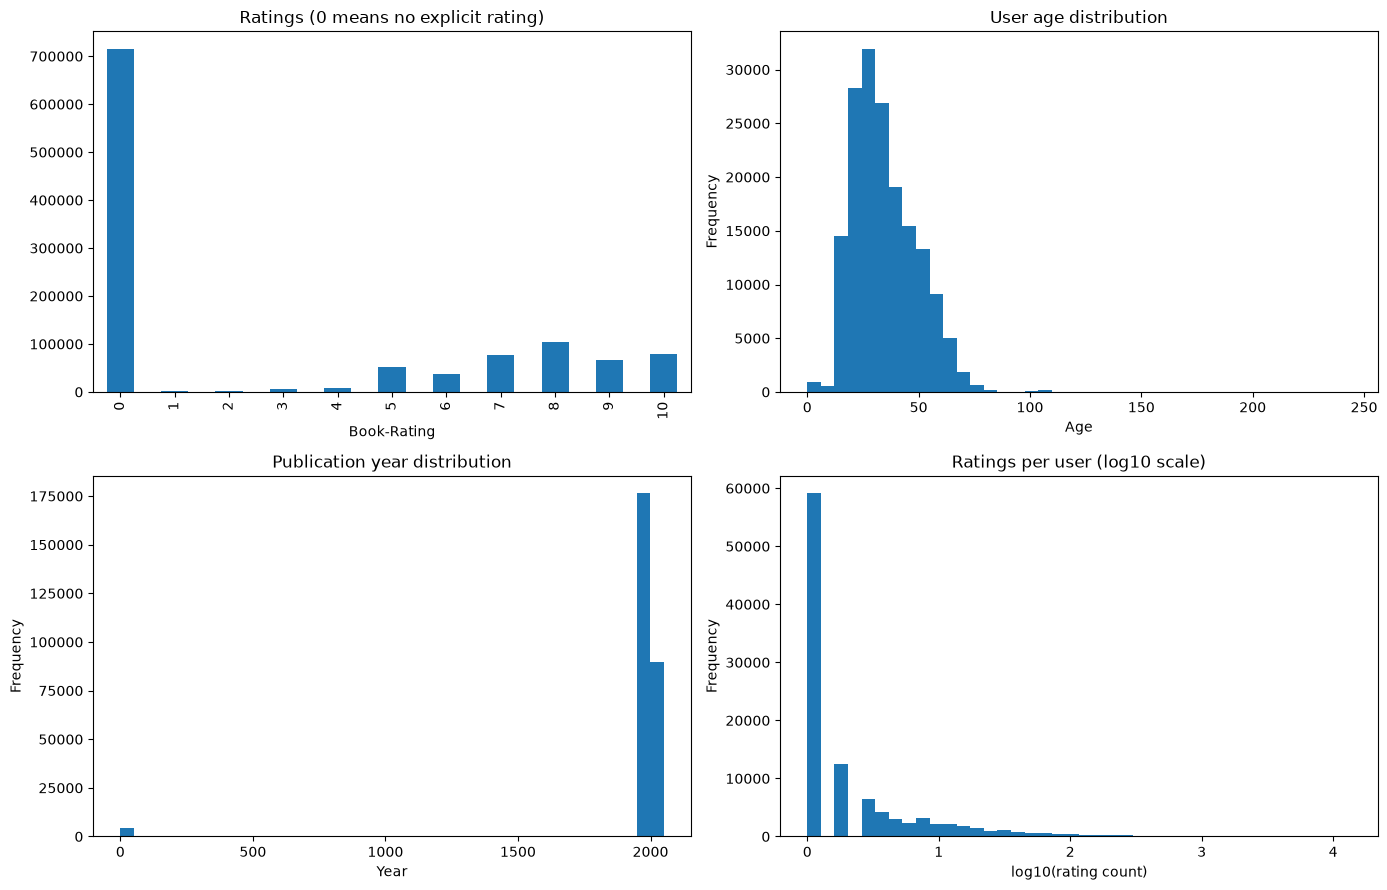

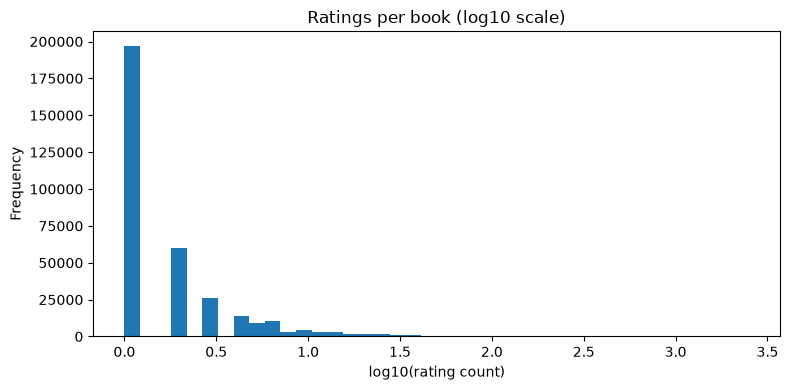

In [3]:
def profile_table(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing_values": frame.isna().sum(),
        "missing_percent": (frame.isna().mean() * 100).round(2),
    })


for name, frame in bronze.items():
    print(f"\n{name.upper()} — shape: {frame.shape}")
    display(profile_table(frame))
    print("Exact duplicate rows:", int(frame.drop(columns=["ingestion_timestamp"])
                                       .duplicated().sum()))

print("\nRating value counts (including zero):")
display(ratings_bronze["Book-Rating"].value_counts(dropna=False).sort_index())

age_values = pd.to_numeric(users_bronze["Age"], errors="coerce")
year_values = pd.to_numeric(books_bronze["Year-Of-Publication"], errors="coerce")
rating_counts_by_user = ratings_bronze.groupby("User-ID").size()
rating_counts_by_book = ratings_bronze.groupby("ISBN").size()
possible_pairs = users_bronze["User-ID"].nunique() * books_bronze["ISBN"].nunique()
observed_pairs = ratings_bronze[["User-ID", "ISBN"]].drop_duplicates().shape[0]
matrix_density = observed_pairs / possible_pairs if possible_pairs else 0

eda_summary = {
    "users_age_missing": int(age_values.isna().sum()),
    "users_age_below_5": int((age_values < 5).sum()),
    "users_age_above_100": int((age_values > 100).sum()),
    "books_year_missing_or_non_numeric": int(year_values.isna().sum()),
    "books_year_zero": int((year_values == 0).sum()),
    "books_year_future": int((year_values > datetime.now().year).sum()),
    "ratings_zero": int((ratings_bronze["Book-Rating"] == 0).sum()),
    "ratings_outside_0_to_10": int(
        (~ratings_bronze["Book-Rating"].between(0, 10)).sum()
    ),
    "ratings_per_user_min_median_max": (
        int(rating_counts_by_user.min()),
        float(rating_counts_by_user.median()),
        int(rating_counts_by_user.max()),
    ),
    "ratings_per_book_min_median_max": (
        int(rating_counts_by_book.min()),
        float(rating_counts_by_book.median()),
        int(rating_counts_by_book.max()),
    ),
    "possible_user_book_pairs": int(possible_pairs),
    "observed_unique_user_book_pairs": int(observed_pairs),
    "matrix_density_percent": round(matrix_density * 100, 6),
}
print("\nEDA findings:")
for key, value in eda_summary.items():
    print(f"- {key}: {value}")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ratings_bronze["Book-Rating"].value_counts().sort_index().plot.bar(
    ax=axes[0, 0], title="Ratings (0 means no explicit rating)"
)
age_values.dropna().plot.hist(
    bins=40, ax=axes[0, 1], title="User age distribution", xlabel="Age"
)
year_values.dropna().plot.hist(
    bins=40, ax=axes[1, 0], title="Publication year distribution",
    xlabel="Year"
)
np.log10(rating_counts_by_user.clip(lower=1)).plot.hist(
    bins=40, ax=axes[1, 1], title="Ratings per user (log10 scale)",
    xlabel="log10(rating count)"
)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
np.log10(rating_counts_by_book.clip(lower=1)).plot.hist(
    bins=40, ax=ax, title="Ratings per book (log10 scale)",
    xlabel="log10(rating count)"
)
plt.tight_layout()
plt.show()

### EDA interpretation and Silver decisions

The printed tables and charts above provide the data-dependent findings:
source dimensions, types, missingness, duplicate rows, rating distribution,
invalid age/year counts, rating-count skew, and matrix sparsity. This dataset
is highly sparse and activity is long-tailed, so Silver uses a minimum of
**10 ratings per user and per book**. The threshold is a practical baseline:
it excludes entities with very little collaborative evidence while retaining
a broad enough catalog. The exact retained counts are reported after cleaning.

## Step 3 — Silver cleaning

Exact duplicates are removed first. Duplicate book identifiers are resolved
by retaining the most complete metadata row; duplicate user-book ratings are
averaged so conflicting repeated observations are not selected arbitrarily.
The 10-rating minimum is applied iteratively to both sides until the resulting
user-book graph satisfies both constraints.

In [4]:
def strip_text_columns(frame, columns):
    for column in columns:
        if column in frame.columns:
            frame[column] = frame[column].astype("string").str.strip()
            frame[column] = frame[column].replace("", pd.NA)
    return frame


users = users_bronze.drop(columns=["ingestion_timestamp"]).drop_duplicates().copy()
books = books_bronze.drop(columns=["ingestion_timestamp"]).drop_duplicates().copy()
ratings = ratings_bronze.drop(columns=["ingestion_timestamp"]).drop_duplicates().copy()

users["User-ID"] = pd.to_numeric(users["User-ID"], errors="coerce")
users = users.dropna(subset=["User-ID"]).drop_duplicates("User-ID", keep="first")
users["Age"] = pd.to_numeric(users["Age"], errors="coerce")
users.loc[~users["Age"].between(5, 100), "Age"] = np.nan
median_age = users["Age"].median()
if pd.isna(median_age):
    raise ValueError("No valid user ages remain; cannot impute age with a median.")
users["Age"] = users["Age"].fillna(median_age)
users = strip_text_columns(users, ["Location"])

location_parts = users["Location"].str.split(",", n=2, expand=True)
location_parts = location_parts.reindex(columns=range(3))
for index, column in enumerate(["City", "State", "Country"]):
    users[column] = location_parts[index].astype("string").str.strip()
    users[column] = users[column].replace("", pd.NA)
users["City"] = users["City"].str.title()
users["State"] = users["State"].map(
    lambda value: value.upper() if isinstance(value, str) and len(value) == 2
    else value.title() if isinstance(value, str) else value
)
users["Country"] = users["Country"].map(
    lambda value: value.upper() if isinstance(value, str) and len(value) <= 3
    else value.title() if isinstance(value, str) else value
)
users = users.drop(columns=["Location"])

books["ISBN"] = books["ISBN"].astype("string").str.strip()
books = books.dropna(subset=["ISBN"])
text_book_columns = [
    column for column in ["Book-Title", "Book-Author", "Publisher"]
    if column in books.columns
]
books = strip_text_columns(books, text_book_columns)
books["Year-Of-Publication"] = pd.to_numeric(
    books["Year-Of-Publication"], errors="coerce"
)
invalid_year = (
    books["Year-Of-Publication"].eq(0)
    | books["Year-Of-Publication"].gt(datetime.now().year)
)
books.loc[invalid_year, "Year-Of-Publication"] = np.nan
image_columns = [column for column in books.columns if column.startswith("Image-URL")]
books = books.drop(columns=image_columns)

if "Book-Title" not in books.columns:
    raise KeyError("Book metadata is missing the required Book-Title column.")
books["_metadata_completeness"] = books.notna().sum(axis=1)
books = (
    books.sort_values("_metadata_completeness", ascending=False, kind="stable")
    .drop_duplicates("ISBN", keep="first")
    .drop(columns="_metadata_completeness")
)

ratings["User-ID"] = pd.to_numeric(ratings["User-ID"], errors="coerce")
ratings["Book-Rating"] = pd.to_numeric(ratings["Book-Rating"], errors="coerce")
ratings["ISBN"] = ratings["ISBN"].astype("string").str.strip()
ratings = ratings.dropna(subset=["User-ID", "ISBN", "Book-Rating"])
ratings = ratings[ratings["Book-Rating"].between(1, 10)].copy()

ratings = ratings[
    ratings["User-ID"].isin(users["User-ID"])
    & ratings["ISBN"].isin(books["ISBN"])
]
conflicting_pairs = int(
    ratings.groupby(["User-ID", "ISBN"])["Book-Rating"].nunique().gt(1).sum()
)
ratings = (
    ratings.groupby(["User-ID", "ISBN"], as_index=False, sort=False)["Book-Rating"]
    .mean()
)

MIN_RATINGS = 10
while not ratings.empty:
    user_counts = ratings.groupby("User-ID").size()
    book_counts = ratings.groupby("ISBN").size()
    keep_users = user_counts[user_counts >= MIN_RATINGS].index
    keep_books = book_counts[book_counts >= MIN_RATINGS].index
    filtered = ratings[
        ratings["User-ID"].isin(keep_users) & ratings["ISBN"].isin(keep_books)
    ]
    if len(filtered) == len(ratings):
        break
    ratings = filtered

active_users = ratings["User-ID"].unique()
active_books = ratings["ISBN"].unique()
users = users[users["User-ID"].isin(active_users)].copy()
books = books[books["ISBN"].isin(active_books)].copy()
if ratings.empty or users.empty or books.empty:
    raise ValueError(
        "Silver filtering produced no ratings; inspect the source data or threshold."
    )

users.to_parquet(SILVER_DIR / "users.parquet", index=False)
books.to_parquet(SILVER_DIR / "books.parquet", index=False)
ratings.to_parquet(SILVER_DIR / "ratings.parquet", index=False)

print(f"Median age used for imputation: {median_age:.1f}")
print(f"Conflicting duplicate user-book pairs averaged: {conflicting_pairs:,}")
print(f"Silver users: {len(users):,}; books: {len(books):,}; ratings: {len(ratings):,}")
print(f"Minimum activity threshold: {MIN_RATINGS} ratings per user and per book")
display(users.head())
display(books.head())
display(ratings.head())

Median age used for imputation: 32.0
Conflicting duplicate user-book pairs averaged: 0
Silver users: 1,820; books: 2,030; ratings: 41,456
Minimum activity threshold: 10 ratings per user and per book


,User-ID,Age,City,State,Country
242,243,32.0,Arden Hills,Minnesota,USA
253,254,24.0,Minneapolis,Minnesota,USA
637,638,20.0,San Diego,California,USA
804,805,34.0,Sonoma,California,USA
881,882,23.0,Berkeley,California,USA


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher
18,0440234743,The Testament,John Grisham,1999.0,Dell
19,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison,1994.0,Plume
26,0971880107,Wild Animus,Rich Shapero,2004.0,Too Far
27,0345402871,Airframe,Michael Crichton,1997.0,Ballantine Books
28,0345417623,Timeline,MICHAEL CRICHTON,2000.0,Ballantine Books


,User-ID,ISBN,Book-Rating
529,277427,002542730X,10.0
532,277427,0060542128,7.0
533,277427,0061009059,9.0
544,277427,0316776963,8.0
545,277427,0345413903,10.0


## Step 4 — Gold model data

The matrix has one row per book and one column per user. Unobserved ratings
remain implicit zeros in a SciPy CSR matrix, avoiding a dense user-book table.
Gold also contains the index mappings and readable book metadata.

In [5]:
books = books.sort_values("ISBN", kind="stable").reset_index(drop=True)
users = users.sort_values("User-ID", kind="stable").reset_index(drop=True)
book_index = pd.DataFrame({
    "ISBN": books["ISBN"],
    "book_idx": np.arange(len(books), dtype=np.int32),
})
user_index = pd.DataFrame({
    "User-ID": users["User-ID"],
    "user_idx": np.arange(len(users), dtype=np.int32),
})

book_to_idx = dict(zip(book_index["ISBN"], book_index["book_idx"]))
user_to_idx = dict(zip(user_index["User-ID"], user_index["user_idx"]))
indexed_ratings = ratings.copy()
indexed_ratings["book_idx"] = indexed_ratings["ISBN"].map(book_to_idx)
indexed_ratings["user_idx"] = indexed_ratings["User-ID"].map(user_to_idx)
if indexed_ratings[["book_idx", "user_idx"]].isna().any().any():
    raise ValueError("Found a rating without a corresponding Gold index.")

rating_matrix = csr_matrix(
    (
        indexed_ratings["Book-Rating"].astype(np.float32),
        (
            indexed_ratings["book_idx"].astype(np.int32),
            indexed_ratings["user_idx"].astype(np.int32),
        ),
    ),
    shape=(len(book_index), len(user_index)),
)
lookup_columns = [
    column for column in ["ISBN", "Book-Title", "Book-Author"]
    if column in books.columns
]
book_lookup = books[lookup_columns].merge(book_index, on="ISBN", validate="one_to_one")

book_index.to_parquet(GOLD_DIR / "book_index.parquet", index=False)
user_index.to_parquet(GOLD_DIR / "user_index.parquet", index=False)
book_lookup.to_parquet(GOLD_DIR / "book_lookup.parquet", index=False)
save_npz(GOLD_DIR / "book_user_rating_matrix.npz", rating_matrix)
with open(GOLD_DIR / "matrix_metadata.json", "w", encoding="utf-8") as file:
    json.dump(
        {
            "shape_book_rows_user_columns": list(rating_matrix.shape),
            "nnz": int(rating_matrix.nnz),
            "density_percent": round(
                rating_matrix.nnz / (rating_matrix.shape[0] * rating_matrix.shape[1])
                * 100,
                6,
            ),
            "minimum_ratings_per_user_and_book": MIN_RATINGS,
        },
        file,
        indent=2,
    )

print("Gold matrix shape (books, users):", rating_matrix.shape)
print("Observed ratings:", f"{rating_matrix.nnz:,}")
print("Gold matrix density:",
      f"{rating_matrix.nnz / (rating_matrix.shape[0] * rating_matrix.shape[1]) * 100:.6f}%")
display(book_lookup.head())

Gold matrix shape (books, users): (2030, 1820)
Observed ratings: 41,456
Gold matrix density: 1.122070%


,ISBN,Book-Title,Book-Author,book_idx
0,0020199600,GREAT GATSBY (REISSUE),F. Scott Fitzgerald,0
1,0020442203,"Lion, the Witch and the Wardrobe",C.S. Lewis,1
2,002542730X,Politically Correct Bedtime Stories: Modern Tales for Our Life and Times,James Finn Garner,2
3,0028604199,Once upon a More Enlightened Time: More Politically Correct Bedtime Stories,James Finn Garner,3
4,0060002050,On a Wicked Dawn (Cynster Novels),Stephanie Laurens,4


## Step 5 — Item-based collaborative filtering

Cosine similarity is computed between sparse book vectors (users are the
features). Recommendations aggregate similarity weighted by the user's
explicit rating, favoring books similar to the user's highly rated books.

In [6]:
if rating_matrix.shape[0] < 2:
    raise ValueError("At least two books are needed to build item similarities.")

neighbors_model = NearestNeighbors(metric="cosine", algorithm="brute")
neighbors_model.fit(rating_matrix)

book_positions = book_lookup.set_index("book_idx")
title_to_indices = {}
for book_idx, row in book_lookup.iterrows():
    title = row["Book-Title"]
    if pd.notna(title):
        title_to_indices.setdefault(str(title).strip().casefold(), []).append(
            int(row["book_idx"])
        )


def _book_title(book_idx):
    return book_positions.loc[book_idx, "Book-Title"]


def similar_books(title, n=10):
    """Return up to n nearest books for an exact, case-insensitive title."""
    if not isinstance(n, int) or n < 1:
        raise ValueError("n must be a positive integer.")
    matches = title_to_indices.get(str(title).strip().casefold())
    if not matches:
        raise ValueError(f"Book title not found in the Gold catalog: {title!r}")
    if len(matches) > 1:
        print(f"Title matches {len(matches)} books; using the first catalog match.")
    source_idx = matches[0]
    neighbor_count = min(n + 1, rating_matrix.shape[0])
    distances, indices = neighbors_model.kneighbors(
        rating_matrix[source_idx], n_neighbors=neighbor_count
    )
    results = []
    for candidate_idx, distance in zip(indices[0], distances[0]):
        if int(candidate_idx) == source_idx:
            continue
        row = book_positions.loc[int(candidate_idx)]
        results.append({
            "ISBN": row["ISBN"],
            "Book-Title": row["Book-Title"],
            "Book-Author": row.get("Book-Author", pd.NA),
            "similarity": float(1 - distance),
        })
        if len(results) == n:
            break
    return pd.DataFrame(results)


def recommend(user_id, n=10, seed_limit=20, neighbor_limit=100):
    """Recommend unrated books using similarity weighted by explicit ratings."""
    if not isinstance(n, int) or n < 1:
        raise ValueError("n must be a positive integer.")
    if user_id not in user_to_idx:
        raise KeyError(f"User ID not found in the Gold data: {user_id!r}")

    user_idx = int(user_to_idx[user_id])
    user_ratings = ratings[ratings["User-ID"] == user_id].copy()
    user_ratings["book_idx"] = user_ratings["ISBN"].map(book_to_idx).astype(int)
    already_read = set(user_ratings["book_idx"].tolist())
    seeds = user_ratings[user_ratings["Book-Rating"] >= 7]
    if seeds.empty:
        seeds = user_ratings.nlargest(seed_limit, "Book-Rating")
    else:
        seeds = seeds.nlargest(seed_limit, "Book-Rating")
    if seeds.empty:
        return pd.DataFrame(columns=["ISBN", "Book-Title", "Book-Author", "score"])

    scores = {}
    for _, seed in seeds.iterrows():
        seed_idx = int(book_to_idx[seed["ISBN"]])
        count = min(neighbor_limit + 1, rating_matrix.shape[0])
        distances, indices = neighbors_model.kneighbors(
            rating_matrix[seed_idx], n_neighbors=count
        )
        for candidate_idx, distance in zip(indices[0], distances[0]):
            candidate_idx = int(candidate_idx)
            similarity = max(0.0, float(1 - distance))
            if (
                similarity <= 0
                or candidate_idx == seed_idx
                or candidate_idx in already_read
            ):
                continue
            scores[candidate_idx] = (
                scores.get(candidate_idx, 0.0)
                + similarity * float(seed["Book-Rating"])
            )

    ranked = sorted(scores.items(), key=lambda item: (-item[1], item[0]))[:n]
    output = []
    for candidate_idx, score in ranked:
        row = book_positions.loc[candidate_idx]
        output.append({
            "ISBN": row["ISBN"],
            "Book-Title": row["Book-Title"],
            "Book-Author": row.get("Book-Author", pd.NA),
            "score": score,
        })
    return pd.DataFrame(output)

example_title = book_lookup["Book-Title"].dropna().iloc[0]
print(f"Books similar to {example_title!r}:")
display(similar_books(example_title, n=10))

Books similar to 'GREAT GATSBY (REISSUE)':


,ISBN,Book-Title,Book-Author,similarity
0,0446322180,Name of the Rose-Nla,Umberto Eco,0.269862
1,055356773X,The Cereal Murders,Diane Mott Davidson,0.197447
2,0345413369,"The Subtle Knife (His Dark Materials, Book 2)",PHILIP PULLMAN,0.189793
3,0156528207,The Little Prince,Antoine de Saint-ExupÃ©ry,0.149917
4,0440967694,The Outsiders,S. E. Hinton,0.147883
5,0553563521,Devil's Waltz (Alex Delaware Novels (Paperback)),Jonathan Kellerman,0.136965
6,0060938455,Fast Food Nation: The Dark Side of the All-American Meal,Eric Schlosser,0.133844
7,0140481389,The Crucible: A Play in Four Acts (Penguin Plays),Arthur Miller,0.133048
8,0688177867,The Book Borrower: A Novel,Alice Mattison,0.131731
9,034543479X,A Widow for One Year,JOHN IRVING,0.127810


## Step 6 — Demo and sanity checks

Three users are selected deterministically from the cleaned dataset. For each,
the notebook shows their highest ratings next to recommendations and verifies
that recommendations are not already rated and reference known catalog items.

In [7]:
demo_users = (
    ratings.groupby("User-ID").size().sort_values(ascending=False).head(3).index
)
if len(demo_users) < 3:
    raise AssertionError("The cleaned dataset must contain at least three users.")

for user_id in demo_users:
    rated = ratings[ratings["User-ID"] == user_id].sort_values(
        "Book-Rating", ascending=False
    )
    high_rated = rated[rated["Book-Rating"] >= 7].head(5)
    if high_rated.empty:
        high_rated = rated.head(5)
    high_rated = high_rated.merge(
        book_lookup[["ISBN", "Book-Title", "Book-Author"]],
        on="ISBN",
        how="left",
        validate="many_to_one",
    )
    recs = recommend(user_id, n=10)
    already_read_isbns = set(rated["ISBN"])
    assert not set(recs["ISBN"]).intersection(already_read_isbns)
    assert set(recs["ISBN"]).issubset(set(book_lookup["ISBN"]))
    assert (recs["score"] >= 0).all()

    print(f"\nUser {user_id} — highly rated books")
    display(high_rated[["Book-Title", "Book-Author", "Book-Rating"]])
    print(f"User {user_id} — recommendations")
    display(recs[["Book-Title", "Book-Author", "score"]])

print("\nAll demo sanity checks passed.")
print("Outputs:")
for directory in (BRONZE_DIR, SILVER_DIR, GOLD_DIR):
    print(f"- {directory.relative_to(ROOT)}/")


User 11676 — highly rated books


,Book-Title,Book-Author,Book-Rating
0,A Wrinkle in Time,Madeleine L'Engle,10.0
1,The Dark Highlander,Karen Marie Moning,10.0
2,Exclusive,Sandra Brown,10.0
3,A Walk to Remember,Nicholas Sparks,10.0
4,The Notebook,Nicholas Sparks,10.0


User 11676 — recommendations


,Book-Title,Book-Author,score
0,The Silver Chair,C. S. Lewis,8.969041
1,The Last Battle,C. S. Lewis,8.141662
2,"The Wide Window (A Series of Unfortunate Events, Book 3)",Lemony Snicket,7.951009
3,Prince Caspian (rack) : The Return to Narnia (Narnia),C. S. Lewis,6.749395
4,The Voyage of the Dawn Treader (rack) (Narnia),C. S. Lewis,6.178797
5,"The Miserable Mill (A Series of Unfortunate Events, Book 4)",Lemony Snicket,5.964422
6,The Horse and His Boy,C. S. Lewis,5.896661
7,"The Lion, the Witch, and the Wardrobe (The Chronicles of Narnia, Book 2)",C. S. Lewis,5.660840
8,"The Ersatz Elevator (A Series of Unfortunate Events, Book 6)",Lemony Snicket,5.654812
9,"The Vile Village (A Series of Unfortunate Events, Book 7)",Lemony Snicket,5.550379



User 16795 — highly rated books


,Book-Title,Book-Author,Book-Rating
0,The Notebook,Nicholas Sparks,10.0
1,That Camden Summer,Lavyrle Spencer,10.0
2,The Dogs of Babel (Today Show Book Club #12),Carolyn Parkhurst,10.0
3,The Lovely Bones: A Novel,Alice Sebold,10.0
4,The Secret Life of Bees,Sue Monk Kidd,10.0


... (3 outputs left out)

,Book-Title,Book-Author,Book-Rating
0,The Sweet Potato Queens' Book of Love,JILL CONNER BROWNE,10.0
1,1984,George Orwell,10.0
2,"Word Freak: Heartbreak, Triumph, Genius, and Obsession in the World of Competitive Scrabble Players",Stefan Fatsis,10.0
3,Harry Potter and the Order of the Phoenix (Book 5),J. K. Rowling,10.0
4,Midnight in the Garden of Good and Evil,John Berendt,10.0


User 95359 — recommendations


,Book-Title,Book-Author,score
0,Into Thin Air : A Personal Account of the Mount Everest Disaster,JON KRAKAUER,10.921900
1,The Phantom Tollbooth,Norton Juster,8.426035
2,How to Be Good,Nick Hornby,6.803187
3,The Poisonwood Bible: A Novel,Barbara Kingsolver,6.344951
4,A Wind in the Door (Laurel Leaf Books),Madeleine L'Engle,6.339459
5,Ella Enchanted (Trophy Newbery),Gail Carson Levine,6.090447
6,"The Fellowship of the Ring (The Lord of the Rings, Part 1)",J. R. R. Tolkien,5.926065
7,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,5.766071
8,Darwin's Radio,Greg Bear,5.387895
9,Zen and the Art of Motorcycle Maintenance: An Inquiry into Values,ROBERT PIRSIG,4.937208



All demo sanity checks passed.
Outputs:
- bronze/
- silver/
- gold/
